In [1]:
import tempfile
from pathlib import Path
import urllib.request
import xarray as xr
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import pyproj

In [3]:
sm_data = xr.open_dataarray("../data/grids_germany_daily_soil_moisture_composite_2014_90-100_v1.nc", engine="netcdf4")
sm_data.shape
sm_data

<xarray.DataArray 'paws' (lyr: 1, time: 365, y: 866, x: 654)> Size: 2GB
[206722860 values with dtype=float64]
Coordinates:
  * lyr                  (lyr) int64 8B 10
  * time                 (time) datetime64[ns] 3kB 2014-01-01 ... 2014-12-31
  * y                    (y) float64 7kB 6.103e+06 6.102e+06 ... 5.238e+06
  * x                    (x) float64 5kB 3.281e+06 3.282e+06 ... 3.934e+06
    lon                  (y, x) float64 5MB ...
    lat                  (y, x) float64 5MB ...
    transverse_mercator  int64 8B ...
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer

In [18]:
print(sm_data.coords)
print(sm_data.attrs)
print(f"dims: {sm_data.dims}")
print(len(sm_data.x))
print(len(sm_data.y))

crs_sm = pyproj.CRS.from_user_input('EPSG:31467')
print(crs_sm)
print(crs_sm.to_epsg())



Coordinates:
  * lyr                  (lyr) int64 8B 10
  * time                 (time) datetime64[ns] 3kB 2014-01-01 ... 2014-12-31
  * y                    (y) float64 7kB 6.103e+06 6.102e+06 ... 5.238e+06
  * x                    (x) float64 5kB 3.281e+06 3.282e+06 ... 3.934e+06
    lon                  (y, x) float64 5MB ...
    lat                  (y, x) float64 5MB ...
    transverse_mercator  int64 8B ...
{'grid_mapping': 'transverse_mercator', 'esri_pe_string': 'PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsches_Hauptdreiecksnetz",DATUM["D_Deutsches_Hauptdreiecksnetz",SPHEROID["Bessel_1841",6377397.155,299.1528128]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Gauss_Kruger"],PARAMETER["False_Easting",3500000.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",9.0],PARAMETER["Scale_Factor",1.0],PARAMETER["Latitude_Of_Origin",0.0],UNIT["Meter",1.0]]', 'standard_name': 'percentage_of_plant_available_water_content_of_soil_layer', 'units

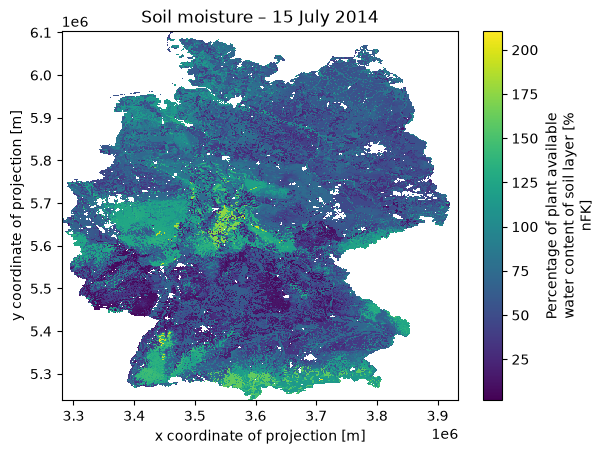

In [28]:
# Select the soil layer and a random day
sm_data.sel(lyr=10,time="2014-07-15").plot()

plt.title("Soil moisture – 15 July 2014")
plt.show()

In [8]:
# import study area bbox
study_area = gpd.read_file("../data/study_area.gpkg", layer="study_area")
bbox = study_area.geometry.iloc[0].bounds
print(study_area.crs)

EPSG:3035


In [39]:
BB_SHAPE = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="bebb_0")
BER_SHAPE = gpd.read_file("../data/brandenburg_shape/pos_1/GRENZE_184201-5683624_ortsteile.gpkg", layer="berlinflaeche_0")
beb = BB_SHAPE.to_crs("EPSG:31467")
berlin = BER_SHAPE.to_crs("EPSG:31467")

<xarray.DataArray 'paws' (y: 269, x: 270)> Size: 581kB
[72630 values with dtype=float64]
Coordinates:
  * y                    (y) float64 2kB 5.958e+06 5.957e+06 ... 5.69e+06
  * x                    (x) float64 2kB 3.641e+06 3.642e+06 ... 3.91e+06
    lon                  (y, x) float64 581kB ...
    lat                  (y, x) float64 581kB ...
    transverse_mercator  int64 8B ...
    time                 datetime64[ns] 8B 2014-07-15
    lyr                  int64 8B 10
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
float64
7.6000000000000005
130.20000000000002


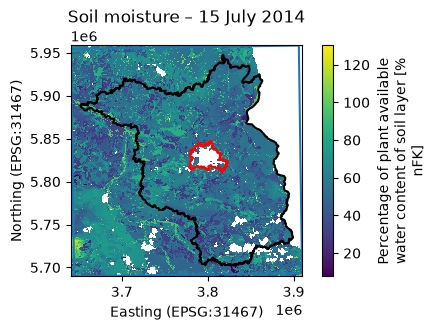

In [40]:
# reproject study box to dwd epsg (31467)
bbox_sm = study_area.to_crs("EPSG:31467")
xmin, ymin, xmax, ymax = bbox_sm.total_bounds

sm_var = sm_data["lyr"]

sm_beb = sm_data.sel(x=slice(xmin,xmax), y=slice(ymax,ymin), lyr=10, time="2014-07-15")


print(sm_beb)
print(sm_beb.dtype)
print(sm_beb.min().values)
print(sm_beb.max().values)



fig, ax = plt.subplots(figsize=(5, 3))

sm_beb.plot(
    ax=ax,
    x="x",
    y="y",
)

bbox_sm.boundary.plot(
    ax=ax,
    linewidth=1.5,
)

beb.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.5,
)

berlin.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=1.5,
)

ax.set_title("Soil moisture – 15 July 2014")
ax.set_xlabel("Easting (EPSG:31467)")
ax.set_ylabel("Northing (EPSG:31467)")

plt.show()



In [ ]:
BASE_URL = "https://opendata.dwd.de/climate_environment/CDC/grids_germany/daily/soil_moisture/composite/"
filename = 

In [3]:
sm_top = xr.open_dataarray("../data/imported/grids_germany_daily_soil_moisture_composite_0-10_v1.nc", engine="netcdf4")

In [14]:
print("Minimum:", float(sm_top.min()))
print("Maximum:", float(sm_top.max()))
print("Mean:", float(sm_top.mean()))
print("Number of values > 100:")
print(int((sm_top > 100).sum()))
print(
    "Percentage of values > 100:",
    float((sm_top > 100).mean() * 100),
    "%"
)

Minimum: -14.700000000000001
Maximum: 355.0
Mean: 78.22951982414126
Number of values > 100:
181393021
Percentage of values > 100: 27.351817298874572 %


In [ ]:
print(sm_top.attrs)
print(sm_top.encoding)

{'grid_mapping': 'transverse_mercator', 'esri_pe_string': 'PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsches_Hauptdreiecksnetz",DATUM["D_Deutsches_Hauptdreiecksnetz",SPHEROID["Bessel_1841",6377397.155,299.1528128]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Gauss_Kruger"],PARAMETER["False_Easting",3500000.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",9.0],PARAMETER["Scale_Factor",1.0],PARAMETER["Latitude_Of_Origin",0.0],UNIT["Meter",1.0]]', 'standard_name': 'percentage_of_plant_available_water_content_of_soil_layer', 'units': '% nFK', 'long_name': 'Percentage of plant available water content of soil layer', 'soil_depth': '0-10'}
{'dtype': dtype('int16'), 'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': True, 'complevel': 9, 'fletcher32': False, 'contiguous': False, 'chunksizes': (1827, 54, 54), 'preferred_chunks': {'time': 1827, 'y': 54, 'x': 54}, 'source': 'c:\\Users\\frank\\Projects\\AIHWS\\po

In [18]:
sm_top.quantile([0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 1])

<xarray.DataArray 'sm_dwd_0_10' (quantile: 9)> Size: 72B
array([-14.7,  -1.6,   2.5,   8.9,  85.9, 130.8, 148. , 173.4, 355. ])
Coordinates:
  * quantile  (quantile) float64 72B 0.0 0.001 0.01 0.05 0.5 0.95 0.99 0.999 1.0
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
    soil_depth:      0-10

In [19]:
negative = sm_top.where(sm_top < 0)

print("Number of negative values:", negative.count().item())
print("Minimum:", sm_top.min().item())

negative_time = (sm_top < 0).sum(dim=("y", "x"))

print(negative_time.sortby(negative_time, ascending=False).head(20))

Number of negative values: 1093864
Minimum: -14.700000000000001
<xarray.DataArray 'sm_dwd_0_10' (time: 20)> Size: 160B
array([22451, 21572, 20079, 18529, 18445, 18387, 17433, 16615, 16401,
       16234, 15262, 14877, 14872, 14488, 14481, 13098, 12816, 12630,
       12126, 11938])
Coordinates:
  * time                 (time) datetime64[ns] 160B 2022-08-14 ... 2018-07-06
    transverse_mercator  int64 8B ...
Attributes:
    grid_mapping:    transverse_mercator
    esri_pe_string:  PROJCS["DHDN_3_Degree_Gauss_Zone_3",GEOGCS["GCS_Deutsche...
    standard_name:   percentage_of_plant_available_water_content_of_soil_layer
    units:           % nFK
    long_name:       Percentage of plant available water content of soil layer
    soil_depth:      0-10
